# 08 - Architectural decisions for VisDrone

The question of this notebook: how should the baseline detectors be changed for this task, and
which of the changes are supported by experiments? Every decision is one run that differs from
its reference run in that decision only, scored with the same evaluator on the same fold-0 and
`val` frames, with the per-clip paired test of notebook 05 (a difference counts when it is at
least two standard errors).

**What is specific about VisDrone.** The EDA (notebook 01) shows that most objects are small:
the median box is about 20 px wide in a 1920 px frame, and in COCO terms most of them are
"small" (below 32 x 32 px). Frames are dense (up to several hundred objects) and taken from
above, so the objects of one class look alike and differ mostly in size. Every decision below is
a hypothesis about one of these properties.

| Decision | Run | Reference | Hypothesis |
|---|---|---|---|
| input 640 -> 1152 px | af1_imgsz1152 | af0_baseline_640 | small objects lose too many pixels at 640 px |
| YOLO: extra stride-4 head (P2) | af2_p2_1152 | af1_imgsz1152 | a 4 px grid places more locations on small objects |
| YOLO: NWD box loss | af3_nwd_1152 | af1_imgsz1152 | IoU is too harsh for tiny boxes |
| YOLO: assigner top-k 5 / 15 | af4_topk5_1152, af4_topk15_1152 | af1_imgsz1152 | small objects cover fewer than 10 good locations |
| query-based detector (RT-DETR-l) | qb0_rtdetr_l_1152 | af1_imgsz1152 | one-to-one matching and global attention help in dense scenes |
| RT-DETR: 500 queries | qb4_q500_default_1152 | qb0_rtdetr_l_1152 | 300 queries limit frames with many objects |
| RT-DETR: extra stride-4 level (P2) | c1_rtdetr_p2_s5_short | p3_rtdetr_s5_short | the stride-8 finest level is too coarse (see tiling below) |
| RT-DETR P2: default initialisation | c2_rtdetr_p2_open_s5_short | c1_rtdetr_p2_s5_short | the silent start of c1 kept the P2 level switched off (section 2.4) |

**Why a P2 level for RT-DETR.** Notebook 07 found that tiling (running the model on 2x2 zoomed
crops, 1.7x zoom) is the largest gain of all inference strategies: +0.021 per-clip AP, better on
all 26 clips, with val AP_small rising from 0.134 to 0.156. The model can recognise these objects
when they are larger, so the limit is resolution inside the network, not the classifier. Tiling
costs 4.5x inference time; a finer feature level gives the network the same resolution once.

**The P2 model** (`configs/models/rtdetr-l-p2.yaml`). The neck of RT-DETR-l is extended by one
more top-down step: the P3 output of the FPN is reduced to 128 channels, upsampled to stride 4
and fused with the backbone stage-1 features (128 channels, stride 4) by a RepC3 block. The
decoder reads four levels (P2, P3, P4, P5). At 1152 px the P2 map is 288 x 288 = 83k tokens,
3.2x more than P3-P5 together, which costs memory in the encoder head (it scores every token to
select the 300 queries); deformable attention only samples 4 points per level and head, so the
decoder cost grows little.

Three details keep the pretrained model intact (`src/train_tools.py`, `load_with_extra_levels`):

1. the new layers are appended after layer 27, so all 941 pretrained tensors load by name;
2. the cross-attention of every decoder layer gets offsets and weights for the new level,
   copied from the old finest level, with attention logits 2 lower, and the projection of the
   new level starts with a zero BatchNorm scale, so at the start the decoder works exactly as the
   pretrained one and the new level is switched on by training;
3. the decoder sets the initial box size of level i to 0.05 * 2^i of the image; a new level 0
   would double the priors of P3-P5, so the base is halved (P2 0.025, P3-P5 unchanged).

Both c1 and its reference p3 use the short schedule of notebook 07 (every 5th frame of folds
1-2, 5 epochs, scored with `last.pt`).

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from src.analysis import classify_errors, error_summary, paired_comparison, per_clip_ap
from src.common import CLASS_NAMES, REPO_ROOT, RUNS_DIR
from src.predict import EVAL_SETS
from src.train_tools import checkpoint, load_config

pd.set_option("display.precision", 4)

## 1. Decision log

In [2]:
DECISIONS = [
    ("input 640 -> 1152 px", "af1_imgsz1152", "af0_baseline_640"),
    ("YOLO: P2 head", "af2_p2_1152", "af1_imgsz1152"),
    ("YOLO: NWD box loss", "af3_nwd_1152", "af1_imgsz1152"),
    ("YOLO: assigner top-k 5", "af4_topk5_1152", "af1_imgsz1152"),
    ("YOLO: assigner top-k 15", "af4_topk15_1152", "af1_imgsz1152"),
    ("query-based (RT-DETR-l)", "qb0_rtdetr_l_1152", "af1_imgsz1152"),
    ("RT-DETR: 500 queries", "qb4_q500_default_1152", "qb0_rtdetr_l_1152"),
    ("RT-DETR: P2 level, silent start", "c1_rtdetr_p2_s5_short", "p3_rtdetr_s5_short"),
    ("RT-DETR: P2 level, default init", "c2_rtdetr_p2_open_s5_short", "p3_rtdetr_s5_short"),
    ("RT-DETR P2: default init vs silent start", "c2_rtdetr_p2_open_s5_short", "c1_rtdetr_p2_s5_short"),
]

FAMILIES = ["anchor_free", "query_based", "pipeline", "custom"]
runs = {}
for config_path in sorted(path for family in FAMILIES for path in (REPO_ROOT / "configs" / family).glob("*.yaml")):
    cfg = load_config(config_path)
    run_dir = RUNS_DIR / cfg["family"] / cfg["name"]
    if (run_dir / "metrics.json").exists():
        runs[cfg["name"]] = {"cfg": cfg, "dir": run_dir, "metrics": json.loads((run_dir / "metrics.json").read_text())}


def clip_ap_of(name):
    ap = {}
    for eval_set in EVAL_SETS:
        detections = json.loads((runs[name]["dir"] / f"predictions_{eval_set}.json").read_text())
        for clip, value in per_clip_ap(EVAL_SETS[eval_set][1], detections).items():
            ap[f"{eval_set}/{clip}"] = value
    return ap


def n_params(name):
    model = torch.load(checkpoint(runs[name]["cfg"]), map_location="cpu", weights_only=False)["model"]
    return sum(p.numel() for p in model.parameters()) / 1e6


clip_ap, rows = {}, []
for decision, new, old in DECISIONS:
    if new not in runs or old not in runs:
        continue
    for name in (new, old):
        if name not in clip_ap:
            clip_ap[name] = clip_ap_of(name)
    paired = paired_comparison({old: clip_ap[old], new: clip_ap[new]}, reference=old).loc[new]
    m_new, m_old = runs[new]["metrics"], runs[old]["metrics"]
    rows.append({
        "decision": decision, "run": new,
        "d_AP": m_new["fold0"]["AP"] - m_old["fold0"]["AP"],
        "d_AP_small": m_new["fold0"]["AP_small"] - m_old["fold0"]["AP_small"],
        "d_val_AP": m_new["val"]["AP"] - m_old["val"]["AP"],
        "d_val_AP_small": m_new["val"]["AP_small"] - m_old["val"]["AP_small"],
        "paired_diff": paired["mean_diff"], "std_err": paired["std_err"],
        "clips_better": int(paired["clips_better"]), "clips_worse": int(paired["clips_worse"]),
        "significant": abs(paired["mean_diff"]) >= 2 * paired["std_err"],
        "params_M": n_params(new), "params_M_ref": n_params(old),
        "ms": m_new["val"]["ms_per_image"], "ms_ref": m_old["val"]["ms_per_image"],
    })
decision_log = pd.DataFrame(rows).set_index("decision")
decision_log

,run,d_AP,d_AP_small,d_val_AP,d_val_AP_small,paired_diff,std_err,clips_better,clips_worse,significant,params_M,params_M_ref,ms,ms_ref
decision,,,,,,,,,,,,,,
input 640 -> 1152 px,af1_imgsz1152,0.0624,0.0261,0.0490,0.0739,0.0601,0.0079,24,2,True,9.4309,9.4309,28.7990,43.6609
YOLO: P2 head,af2_p2_1152,-0.0090,-0.0022,-0.0191,-0.0146,-0.0162,0.0080,7,19,True,9.5766,9.4309,26.9310,28.7990
YOLO: NWD box loss,af3_nwd_1152,0.0046,0.0101,-0.0098,-0.0161,0.0124,0.0091,15,11,False,9.4309,9.4309,29.8080,28.7990
YOLO: assigner top-k 5,af4_topk5_1152,0.0035,0.0028,0.0105,-0.0210,0.0062,0.0069,15,11,False,9.4309,9.4309,27.4198,28.7990
YOLO: assigner top-k 15,af4_topk15_1152,0.0017,-0.0051,0.0046,-0.0215,0.0084,0.0073,17,9,False,9.4309,9.4309,30.7744,28.7990
query-based (RT-DETR-l),qb0_rtdetr_l_1152,0.0614,0.0171,0.0657,0.0128,0.0541,0.0060,24,2,True,32.8225,9.4309,58.3827,28.7990
RT-DETR: 500 queries,qb4_q500_default_1152,0.0081,-0.0066,-0.0160,-0.0248,0.0028,0.0064,12,14,False,32.8225,32.8225,58.2475,58.3827
"RT-DETR: P2 level, silent start",c1_rtdetr_p2_s5_short,-0.0015,-0.0040,-0.0394,0.0171,0.0012,0.0076,13,13,False,33.6126,32.8225,63.1435,61.0934
"RT-DETR: P2 level, default init",c2_rtdetr_p2_open_s5_short,-0.0047,-0.0051,-0.0083,0.0177,0.0006,0.0057,12,14,False,33.6126,32.8225,138.9242,61.0934


## 2. The P2 level of RT-DETR in detail

### 2.1 Training curves

Ultralytics mAP@[.5:.95] on every 20th fold-0 frame after every epoch.

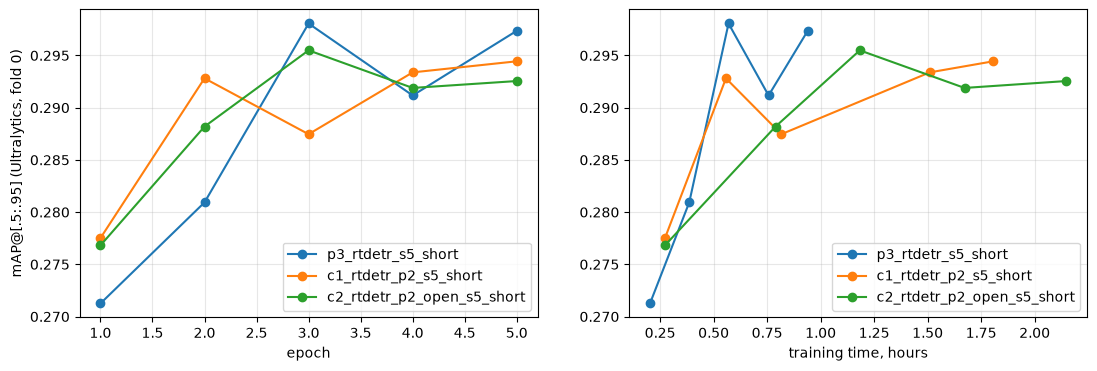

In [3]:
P2_RUNS = ["p3_rtdetr_s5_short", "c1_rtdetr_p2_s5_short", "c2_rtdetr_p2_open_s5_short"]
p2_runs = [name for name in P2_RUNS if name in runs]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name in p2_runs:
    curve = pd.read_csv(runs[name]["dir"] / "results.csv")
    curve.columns = curve.columns.str.strip()
    axes[0].plot(curve["epoch"], curve["metrics/mAP50-95(B)"], marker="o", label=name)
    axes[1].plot(curve["time"] / 3600, curve["metrics/mAP50-95(B)"], marker="o", label=name)
axes[0].set_xlabel("epoch")
axes[1].set_xlabel("training time, hours")
axes[0].set_ylabel("mAP@[.5:.95] (Ultralytics, fold 0)")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
plt.show()

### 2.2 Where the difference comes from: size, class, recall

AP by COCO size and by class, and the simplified TIDE error split of notebook 05 at score >= 0.3.
If the P2 level does what it is meant to do, the gain is in AP_small and in the recall of small
objects, and AP_large does not change.

In [4]:
size_cols = ["AP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large"]
by_size = pd.concat({eval_set: pd.DataFrame({name: {c: runs[name]["metrics"][eval_set][c] for c in size_cols}
                                             for name in p2_runs}).T for eval_set in EVAL_SETS}, axis=1)
display(by_size)

per_class = pd.DataFrame({name: {c: runs[name]["metrics"]["fold0"][f"AP_{c}"] for c in CLASS_NAMES}
                          for name in p2_runs}).T
per_class

fold0                                     \
                                AP    AP50    AP75 AP_small AP_medium   
p3_rtdetr_s5_short          0.2953  0.5339  0.2796   0.0891    0.2303   
c1_rtdetr_p2_s5_short       0.2938  0.5287  0.2827   0.0850    0.2375   
c2_rtdetr_p2_open_s5_short  0.2906  0.5327  0.2780   0.0839    0.2304   

                                        val                           \
                           AP_large      AP    AP50    AP75 AP_small   
p3_rtdetr_s5_short           0.4090  0.2822  0.5226  0.2639   0.1286   
c1_rtdetr_p2_s5_short        0.3920  0.2429  0.4669  0.2204   0.1457   
c2_rtdetr_p2_open_s5_short   0.4114  0.2739  0.5186  0.2521   0.1463   

                                               
                           AP_medium AP_large  
p3_rtdetr_s5_short            0.2318   0.4921  
c1_rtdetr_p2_s5_short         0.2238   0.4191  
c2_rtdetr_p2_open_s5_short    0.2341   0.4660

,person,bicycle,car,van,truck,tricycle,bus,motor
p3_rtdetr_s5_short,0.2433,0.0978,0.5283,0.2513,0.2502,0.2977,0.5331,0.1606
c1_rtdetr_p2_s5_short,0.2405,0.0863,0.5239,0.2528,0.2455,0.2875,0.5510,0.1626
c2_rtdetr_p2_open_s5_short,0.2409,0.0933,0.5203,0.2470,0.2373,0.2898,0.5501,0.1458


In [5]:
gt_path = EVAL_SETS["fold0"][1]
error_rows = []
for name in p2_runs:
    detections = json.loads((runs[name]["dir"] / "predictions_fold0.json").read_text())
    det_table, gt_table = classify_errors(gt_path, detections, score_thr=0.3)
    error_rows.append({"run": name, **error_summary(det_table, gt_table)})
errors = pd.DataFrame(error_rows).set_index("run")
errors

,tp,duplicate,class,location,background,ignored,missed,recall,recall_small,recall_medium,recall_large
run,,,,,,,,,,,
p3_rtdetr_s5_short,28787,1336,6694,4206,15216,12001,8854,0.7648,0.5927,0.7770,0.9095
c1_rtdetr_p2_s5_short,29096,1585,6553,4959,18633,14570,8545,0.7730,0.5977,0.7860,0.9175
c2_rtdetr_p2_open_s5_short,28531,887,6407,4276,15695,11547,9110,0.7580,0.5844,0.7691,0.9093


### 2.3 Which clips gain and which lose

Per-clip AP of both models, sorted by the difference. The clips at both ends are the failure and
success cases to look at.

In [6]:
gt_objects = {}
for eval_set, (_, path) in EVAL_SETS.items():
    gt = json.loads(path.read_text())
    video = {img["id"]: img["video"] for img in gt["images"]}
    sizes = pd.DataFrame([{"clip": f"{eval_set}/{video[a['image_id']]}", "side": np.sqrt(a["area"])}
                          for a in gt["annotations"] if not a["iscrowd"]])
    for clip, group in sizes.groupby("clip"):
        gt_objects[clip] = {"objects": len(group), "median_side_px": group["side"].median()}

old = p2_runs[0]
for new in p2_runs[1:]:
    per_clip = pd.DataFrame({old: clip_ap[old], new: clip_ap[new]})
    per_clip["diff"] = per_clip[new] - per_clip[old]
    per_clip = per_clip.sort_values("diff").join(pd.DataFrame(gt_objects).T)
    display(per_clip)
    print(f"{new}: correlation of the gain with the median object size:",
          round(per_clip["diff"].corr(per_clip["median_side_px"]), 3))

,p3_rtdetr_s5_short,c1_rtdetr_p2_s5_short,diff,objects,median_side_px
val/uav0000305_00000_v,0.3543,0.2614,-9.2921e-02,1290.0,76.9805
fold0/uav0000150_02310_v,0.3862,0.3249,-6.1312e-02,3818.0,60.1124
val/uav0000117_02622_v,0.2895,0.2575,-3.1974e-02,3460.0,64.8884
fold0/uav0000266_03598_v,0.4762,0.4477,-2.8541e-02,358.0,80.5854
fold0/uav0000138_00000_v,0.3417,0.3202,-2.1591e-02,3142.0,45.5961
fold0/uav0000366_00001_v,0.3423,0.3240,-1.8292e-02,2322.0,73.0616
fold0/uav0000013_01392_v,0.3799,0.3623,-1.7608e-02,285.0,44.8999
fold0/uav0000288_00001_v,0.2301,0.2133,-1.6738e-02,6594.0,46.4758
fold0/uav0000315_00000_v,0.2735,0.2593,-1.4211e-02,2649.0,40.8044
val/uav0000339_00001_v,0.2674,0.2564,-1.0964e-02,2406.0,48.6724


c1_rtdetr_p2_s5_short: correlation of the gain with the median object size: -0.373


,p3_rtdetr_s5_short,c2_rtdetr_p2_open_s5_short,diff,objects,median_side_px
fold0/uav0000013_01392_v,0.3799,0.3289,-0.0509,285.0,44.8999
val/uav0000117_02622_v,0.2895,0.2438,-0.0457,3460.0,64.8884
val/uav0000305_00000_v,0.3543,0.3222,-0.0321,1290.0,76.9805
fold0/uav0000309_00000_v,0.3744,0.3587,-0.0157,1743.0,47.7284
val/uav0000137_00458_v,0.3504,0.3352,-0.0152,4858.0,73.2939
fold0/uav0000150_02310_v,0.3862,0.3717,-0.0144,3818.0,60.1124
fold0/uav0000281_00460_v,0.2997,0.2872,-0.0125,2082.0,68.7931
fold0/uav0000288_00001_v,0.2301,0.2207,-0.0094,6594.0,46.4758
fold0/uav0000315_00000_v,0.2735,0.2654,-0.0080,2649.0,40.8044
val/uav0000086_00000_v,0.2987,0.2941,-0.0046,4619.0,39.9124


c2_rtdetr_p2_open_s5_short: correlation of the gain with the median object size: -0.246


### 2.4 Does the decoder use the new level?

Three checks on the trained models, on every 30th val and every 40th fold-0 frame:

- the BatchNorm scale of each level's input projection: the P2 scale of c1 started at 0, so its
  size after training shows how strongly the P2 features are switched on;
- the share of attention mass the deformable cross-attention puts on each level, averaged over
  the queries, heads and decoder layers: how much the decoder reads from each level;
- the level each of the 300 selected queries comes from: the encoder scores every token of every
  level and the decoder starts from the 300 best, so this shows where the detections start.

In [7]:
import cv2
from ultralytics import RTDETR

from src.predict import eval_images

probe_frames = [path for _, path in eval_images("val")[::30] + eval_images("fold0")[::40]]


def probe(name):
    model = RTDETR(str(checkpoint(runs[name]["cfg"])))
    model.predict(cv2.imread(str(probe_frames[0])), imgsz=1152, verbose=False)
    head = model.predictor.model.model.model[-1]
    levels = ["P2", "P3", "P4", "P5"][-head.nl:]
    scales = pd.Series([proj[1].weight.abs().mean().item() for proj in head.input_proj], index=levels)
    shares, selected = [], []

    # Attention share per level from the softmax over levels and points of every head
    attn = head.decoder.layers[0].cross_attn
    def level_share(module, inputs, output):
        weights = output.float().view(*output.shape[:2], attn.n_heads, attn.n_levels * attn.n_points).softmax(-1)
        weights = weights.view(*output.shape[:2], attn.n_heads, attn.n_levels, attn.n_points)
        shares.append(weights.sum(-1).mean((0, 1, 2)).cpu())

    # Level of every selected query, recomputed from the encoder scores as in the decoder
    select = head._get_decoder_input
    def select_and_record(feats, shapes, *args, **kwargs):
        scores = head.enc_score_head(head.enc_output(head.valid_mask * feats)).max(-1).values
        top = scores.topk(head.num_queries, dim=1).indices[0]
        bounds = torch.tensor(np.cumsum([h * w for h, w in shapes]), device=top.device)
        selected.append(np.bincount(torch.bucketize(top, bounds, right=True).cpu().numpy(), minlength=head.nl))
        return select(feats, shapes, *args, **kwargs)

    hooks = [layer.cross_attn.attention_weights.register_forward_hook(level_share) for layer in head.decoder.layers]
    head._get_decoder_input = select_and_record
    for path in probe_frames:
        model.predict(cv2.imread(str(path)), imgsz=1152, verbose=False)
    for hook in hooks:
        hook.remove()

    return pd.DataFrame({"bn_scale": scales, "attention_share": torch.stack(shares).mean(0).numpy(),
                         "queries_per_frame": np.mean(selected, axis=0)})


probes = pd.concat({name: probe(name) for name in p2_runs})
probes

bn_scale  attention_share  queries_per_frame
p3_rtdetr_s5_short         P3    0.8738           0.5586           154.8537
                           P4    0.8709           0.2416            36.0000
                           P5    0.9268           0.1998           109.1463
c1_rtdetr_p2_s5_short      P2    0.0149           0.1362             0.3171
                           P3    0.8738           0.4646           168.1707
                           P4    0.8713           0.2245            17.0244
                           P5    0.9270           0.1747           114.4878
c2_rtdetr_p2_open_s5_short P2    0.9971           0.0520            14.2683
                           P3    0.8742           0.5123           157.6585
                           P4    0.8713           0.2572            18.0000
                           P5    0.9277           0.1786           110.0732

### 2.5 Cost

Parameters, inference time at batch 1 (FP16) and training time per epoch against the reference
(median over the epochs, because other jobs shared the GPU during some of them).

In [8]:
cost = []
for name in p2_runs:
    curve = pd.read_csv(runs[name]["dir"] / "results.csv")
    curve.columns = curve.columns.str.strip()
    cost.append({"run": name, "params_M": n_params(name), "ms_per_image": runs[name]["metrics"]["val"]["ms_per_image"],
                 "minutes_per_epoch": curve["time"].diff().fillna(curve["time"]).median() / 60})
pd.DataFrame(cost).set_index("run")

,params_M,ms_per_image,minutes_per_epoch
run,,,
p3_rtdetr_s5_short,32.8225,61.0934,11.0153
c1_rtdetr_p2_s5_short,33.6126,63.1435,17.0952
c2_rtdetr_p2_open_s5_short,33.6126,138.9242,28.5258


## 3. Findings

**Decisions that are supported by the experiments**

- **Input resolution 1152 px instead of 640 px**: +0.060 per-clip AP, 24 of 26 clips better. The
  largest single change, because most VisDrone objects are below 32 px at full resolution.
- **A query-based detector (RT-DETR-l) instead of YOLO11s**: +0.054, 24 of 26 clips better,
  mostly through recall of small objects in dense frames.

**Decisions that are rejected**

- **YOLO P2 head**: -0.016 +- 0.008, worse on 19 of 26 clips (notebook 05). A new, randomly
  initialised stride-4 head has to learn from scratch, and its 4x denser grid adds candidates to
  the assigner that are mostly background.
- **NWD loss, assigner top-k, 500 queries**: all within the noise (|diff| < 2 standard errors).
- **RT-DETR P2 level with a silent start (c1)**: +0.001 +- 0.008, 13 clips better and 13 worse.
  The analysis in section 2.4 shows why: the BatchNorm scale of the P2 projection grew only from
  0 to 0.015, so all P2 tokens stayed almost the same vector, got the same encoder score, and won
  0.3 of the 300 queries per frame. A token that is never selected gets no box or class loss, so
  the level could only learn through the cross-attention, which reads a nearly constant vector
  from P2 (14% of the attention). The initialisation that was meant to protect the pretrained
  decoder kept the new level switched off. The per-clip differences (-0.09 to +0.11, larger
  losses on clips with large objects) are the noise of two training runs, not an effect of P2.
- **RT-DETR P2 level with the default initialisation (c2)**: +0.001 +- 0.006 against p3, 12
  clips better and 14 worse; -0.001 +- 0.005 against c1. The level is now switched on: the
  BatchNorm scale of the P2 projection is 1.00 (0.015 in c1) and P2 wins 14 of the 300 queries
  per frame (0.3 in c1). But these queries have a mean score of 0.02 and give almost no
  detections above 0.3, so the decoder has not learned to use them in the short schedule. The
  stride-8 level P3 already covers the small objects at 1152 px input (median side of its
  confident detections 0.018 of the input, about 21 px), and tiling at inference recovers more
  small objects (+0.026 AP on fold 0) for no training cost. P2 is not part of the final detector
  design; c1 and c2 enter the final ensemble only as two of its 18 runs (notebook 07, section 3),
  where a run that is as good as p3 but trained differently adds variety.

**Failure cases.** The clip with the largest loss of c1 (val uav0000305, -0.09) has the largest
objects (median side 77 px); with c2 the loss on this clip shrinks to -0.03, so the c1 loss was
mostly run-to-run noise. One gain repeats in both P2 runs: fold-0 clip uav0000079 (+0.11 for c1
and c2). As the P2 queries give almost no confident detections, this gain does not come from
P2 boxes; it is a single clip and does not change the mean.

**Cost.** c1 and c2 have the same architecture, so the speed of c2 in section 2.5 (139 ms per
image, 29 minutes per epoch, against 63 ms and 17 minutes for c1) is not a property of the model:
something else was using the machine during that run. Use the c1 numbers for the cost of P2.